In [8]:
import kagglehub
path = kagglehub.dataset_download("hopesb/student-depression-dataset")

Using Colab cache for faster access to the 'student-depression-dataset' dataset.


In [9]:
import os
os.listdir(path)

['Student Depression Dataset.csv']

In [10]:
import pandas as pd
df=pd.read_csv(path+'/Student Depression Dataset.csv')

In [11]:
df.head(3)

,id,Gender,Age,City,Profession,Academic Pressure,Work Pressure,CGPA,Study Satisfaction,Job Satisfaction,Sleep Duration,Dietary Habits,Degree,Have you ever had suicidal thoughts ?,Work/Study Hours,Financial Stress,Family History of Mental Illness,Depression
0,2,Male,33.0,Visakhapatnam,Student,5.0,0.0,8.97,2.0,0.0,5-6 hours,Healthy,B.Pharm,Yes,3.0,1.0,No,1
1,8,Female,24.0,Bangalore,Student,2.0,0.0,5.90,5.0,0.0,5-6 hours,Moderate,BSc,No,3.0,2.0,Yes,0
2,26,Male,31.0,Srinagar,Student,3.0,0.0,7.03,5.0,0.0,Less than 5 hours,Healthy,BA,No,9.0,1.0,Yes,0


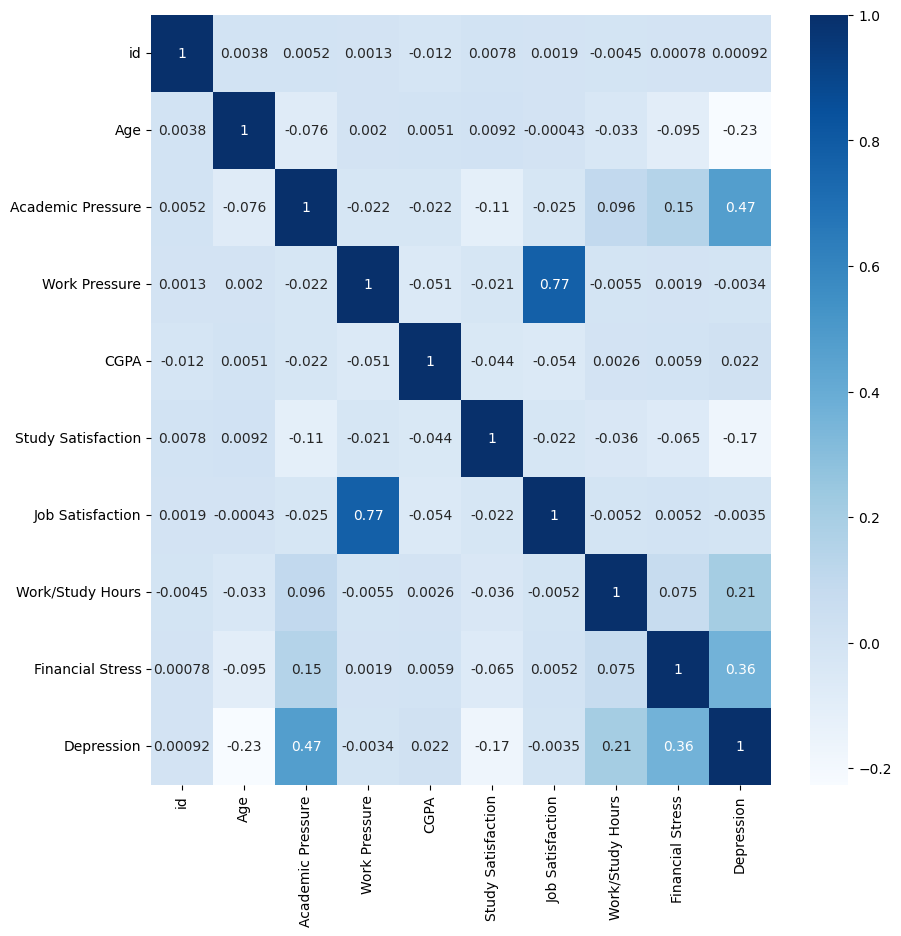

In [12]:
import seaborn as sns
import matplotlib.pyplot as plt
plt.figure(figsize=(10,10))
corr=df.corr(numeric_only=True)
sns.heatmap(corr,annot=True,cmap='Blues')
plt.show()


## We can simply remove id
## Age and Study Satisfaction is quite essential column for us

In [13]:
df['Profession'].value_counts()

,count
Profession,
Student,27870
Architect,8
Teacher,6
Digital Marketer,3
Chef,2
Content Writer,2
Pharmacist,2
Doctor,2
UX/UI Designer,1


## As most of the prefession involves student only so we can remove this column as well

In [14]:
df.drop(columns=['Profession','id'],inplace=True)

In [15]:
df.shape

(27901, 16)

In [16]:
df.head()

,Gender,Age,City,Academic Pressure,Work Pressure,CGPA,Study Satisfaction,Job Satisfaction,Sleep Duration,Dietary Habits,Degree,Have you ever had suicidal thoughts ?,Work/Study Hours,Financial Stress,Family History of Mental Illness,Depression
0,Male,33.0,Visakhapatnam,5.0,0.0,8.97,2.0,0.0,5-6 hours,Healthy,B.Pharm,Yes,3.0,1.0,No,1
1,Female,24.0,Bangalore,2.0,0.0,5.90,5.0,0.0,5-6 hours,Moderate,BSc,No,3.0,2.0,Yes,0
2,Male,31.0,Srinagar,3.0,0.0,7.03,5.0,0.0,Less than 5 hours,Healthy,BA,No,9.0,1.0,Yes,0
3,Female,28.0,Varanasi,3.0,0.0,5.59,2.0,0.0,7-8 hours,Moderate,BCA,Yes,4.0,5.0,Yes,1
4,Female,25.0,Jaipur,4.0,0.0,8.13,3.0,0.0,5-6 hours,Moderate,M.Tech,Yes,1.0,1.0,No,0


In [17]:
df.isnull().sum()

,0
Gender,0
Age,0
City,0
Academic Pressure,0
Work Pressure,0
CGPA,0
Study Satisfaction,0
Job Satisfaction,0
Sleep Duration,0
Dietary Habits,0


In [18]:
df=df[df['Financial Stress'].isnull()!=True]

In [19]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 27898 entries, 0 to 27900
Data columns (total 16 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   Gender                                 27898 non-null  object 
 1   Age                                    27898 non-null  float64
 2   City                                   27898 non-null  object 
 3   Academic Pressure                      27898 non-null  float64
 4   Work Pressure                          27898 non-null  float64
 5   CGPA                                   27898 non-null  float64
 6   Study Satisfaction                     27898 non-null  float64
 7   Job Satisfaction                       27898 non-null  float64
 8   Sleep Duration                         27898 non-null  object 
 9   Dietary Habits                         27898 non-null  object 
 10  Degree                                 27898 non-null  object 
 11  Have yo

In [20]:
categorical=[i for i in df.columns if df[i].dtype=='O']
numerical=[i for i in df.columns if i not in categorical]
numerical

['Age',
 'Academic Pressure',
 'Work Pressure',
 'CGPA',
 'Study Satisfaction',
 'Job Satisfaction',
 'Work/Study Hours',
 'Financial Stress',
 'Depression']

In [21]:
for i in numerical:
  if i not in ['Age','CGPA']:
    print(f"For {i} : {df[i].unique()}")

For Academic Pressure : [5. 2. 3. 4. 1. 0.]
For Work Pressure : [0. 5. 2.]
For Study Satisfaction : [2. 5. 3. 4. 1. 0.]
For Job Satisfaction : [0. 3. 4. 2. 1.]
For Work/Study Hours : [ 3.  9.  4.  1.  0. 12.  2. 11. 10.  6.  8.  5.  7.]
For Financial Stress : [1. 2. 5. 3. 4.]
For Depression : [1 0]


## We can convert the datatype of these columns since they are containing integers

In [22]:
for i in numerical:
  if i not in ['Age','CGPA']:
    df[i]=df[i].astype('int32')
  else:
    df[i]=df[i].astype('float32')

In [23]:
df.duplicated().sum()

np.int64(0)

## There are no duplicates

In [24]:
print(f"Categorical Columns : {categorical}")

Categorical Columns : ['Gender', 'City', 'Sleep Duration', 'Dietary Habits', 'Degree', 'Have you ever had suicidal thoughts ?', 'Family History of Mental Illness']


In [25]:
df['Gender'].value_counts()

,count
Gender,
Male,15546
Female,12352


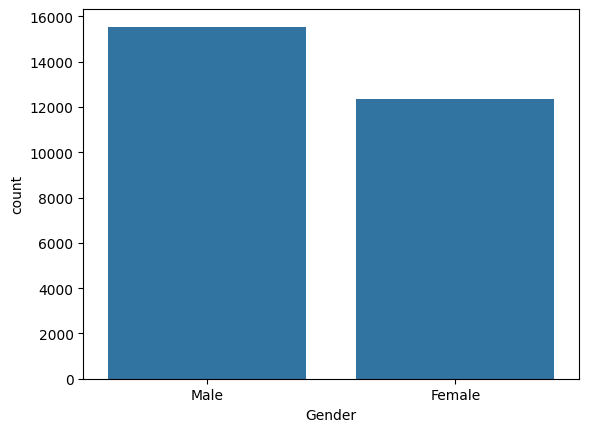

In [26]:
import seaborn as sns
import matplotlib.pyplot as plt
sns.countplot(df,x='Gender')
plt.show()

## We can visualize that gender ratio is not uniformly distributed.
## Males are more than females.

In [27]:
df['City'].value_counts()

,count
City,
Kalyan,1570
Srinagar,1372
Hyderabad,1339
Vasai-Virar,1290
Lucknow,1155
Thane,1139
Ludhiana,1111
Agra,1094
Surat,1078


## Most of the people are from Kalyan,followed by Srinagar, Hyderabad and etc

In [28]:
df['Sleep Duration'].value_counts()

,count
Sleep Duration,
Less than 5 hours,8309
7-8 hours,7346
5-6 hours,6181
More than 8 hours,6044
Others,18


## Mostly people sleep for around less than 5 hours
## Some people are falling in the range others, we can go and remove them since all ranges are covered and this others category can be considered as inappropriate value.

In [29]:
df=df[df['Sleep Duration']!='Others']

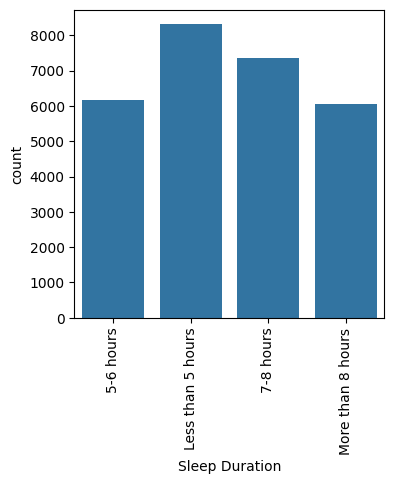

In [30]:
plt.figure(figsize=(4,4))
sns.countplot(df,x='Sleep Duration')
plt.xticks(rotation=90)
plt.show()

In [31]:
df['Dietary Habits'].value_counts()

,count
Dietary Habits,
Unhealthy,10308
Moderate,9914
Healthy,7646
Others,12


## We can see that most of the people are coming out to be Unhealthy.
## Few Individuals again lie in inappropriate categories others

In [32]:
df=df[df['Dietary Habits']!='Others']

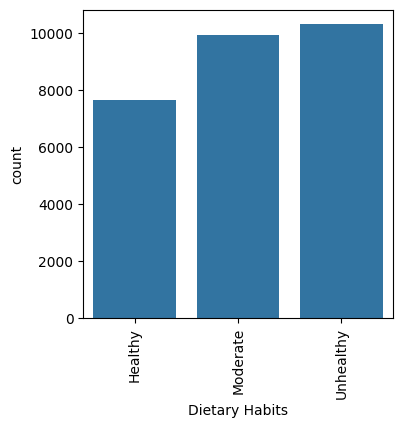

In [33]:
plt.figure(figsize=(4,4))
sns.countplot(df,x='Dietary Habits')
plt.xticks(rotation=90)
plt.show()

In [34]:
df['Degree'].value_counts()

,count
Degree,
Class 12,6079
B.Ed,1864
B.Com,1504
B.Arch,1476
BCA,1431
MSc,1189
B.Tech,1151
MCA,1041
M.Tech,1020


## Most of the students are from Class 12th.
## A number of degrees are being pursued.


In [35]:
df['Family History of Mental Illness'].value_counts()

,count
Family History of Mental Illness,
No,14378
Yes,13490


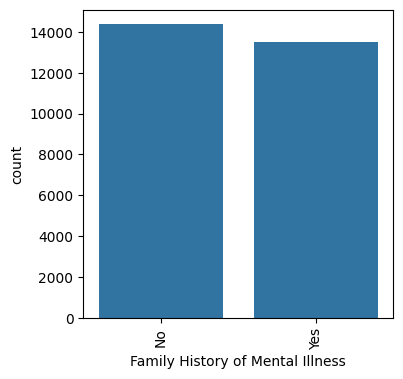

In [36]:
plt.figure(figsize=(4,4))
sns.countplot(df,x='Family History of Mental Illness')
plt.xticks(rotation=90)
plt.show()

## Almost half of the students are belonging to families with mental illness

In [37]:
df['Have you ever had suicidal thoughts ?'].value_counts()

,count
Have you ever had suicidal thoughts ?,
Yes,17635
No,10233


## More than half of the students have come across a thought of suicide in their mindset. That's too crazzzy!

In [38]:
df.to_csv('depressed.csv')

In [39]:
print(f"Numerical Columns are : {numerical}")

Numerical Columns are : ['Age', 'Academic Pressure', 'Work Pressure', 'CGPA', 'Study Satisfaction', 'Job Satisfaction', 'Work/Study Hours', 'Financial Stress', 'Depression']


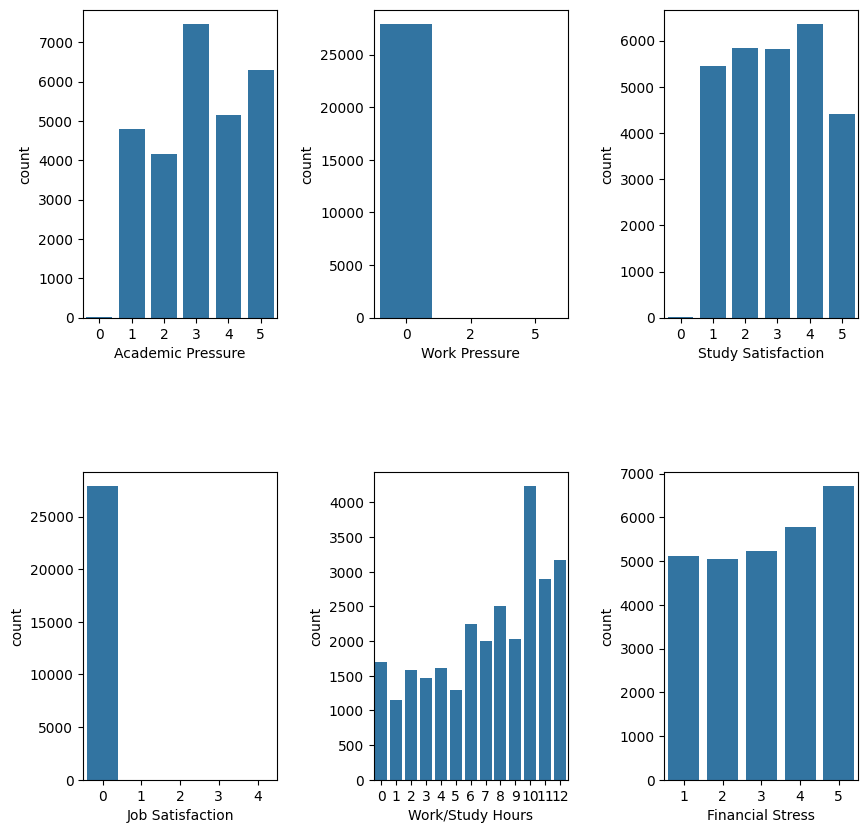

In [40]:
fig,ax=plt.subplots(2,3,figsize=(10,10))
sns.countplot(df,x='Academic Pressure',ax=ax[0,0])
sns.countplot(df,x='Work Pressure',ax=ax[0,1])
sns.countplot(df,x='Study Satisfaction',ax=ax[0,2])
sns.countplot(df,x='Job Satisfaction',ax=ax[1,0])
sns.countplot(df,x='Work/Study Hours',ax=ax[1,1])
sns.countplot(df,x='Financial Stress',ax=ax[1,2])
plt.subplots_adjust(wspace=0.5,hspace=0.5)
plt.show()

## We can consider these columns as Ordered Categorical columns only.

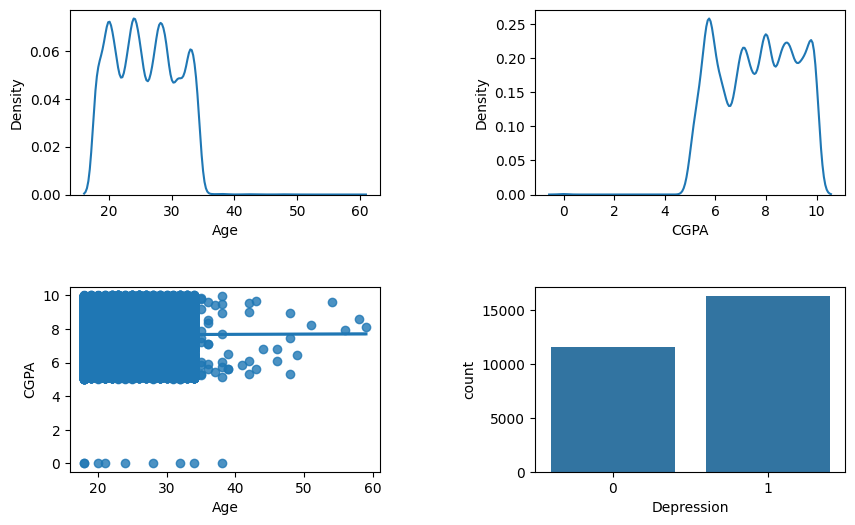

In [41]:
fig,ax=plt.subplots(2,2,figsize=(10,6))
sns.kdeplot(df,x='Age',ax=ax[0,0])
sns.kdeplot(df,x='CGPA',ax=ax[0,1])
sns.regplot(df,x='Age',y='CGPA',ax=ax[1,0])
sns.countplot(df,x='Depression',ax=ax[1,1])
plt.subplots_adjust(wspace=0.5,hspace=0.5)
plt.show()

## Almost majority of the population is in the age group less than 40 and greater than 15.
## Most of the people are scoring CGPA more than 4.
## People in the Age range 50-60 exits as well and are scoring CGPPA greater than 8.
## Depression column data is not uniformly distributed. More people have depression.

In [42]:
df[(df['Age']>50) & (df['CGPA']>8)]

,Gender,Age,City,Academic Pressure,Work Pressure,CGPA,Study Satisfaction,Job Satisfaction,Sleep Duration,Dietary Habits,Degree,Have you ever had suicidal thoughts ?,Work/Study Hours,Financial Stress,Family History of Mental Illness,Depression
2909,Female,58.0,Chennai,4,0,8.58,1,0,7-8 hours,Healthy,Class 12,No,4,4,No,0
4386,Female,51.0,Bhopal,2,0,8.26,3,0,Less than 5 hours,Moderate,MBBS,Yes,5,5,Yes,0
9238,Male,59.0,Nashik,1,0,8.14,1,0,5-6 hours,Unhealthy,PhD,Yes,10,4,Yes,0
13499,Male,54.0,Agra,5,0,9.60,2,0,More than 8 hours,Unhealthy,B.Ed,Yes,9,3,Yes,0


In [43]:
df.sample()

,Gender,Age,City,Academic Pressure,Work Pressure,CGPA,Study Satisfaction,Job Satisfaction,Sleep Duration,Dietary Habits,Degree,Have you ever had suicidal thoughts ?,Work/Study Hours,Financial Stress,Family History of Mental Illness,Depression
12664,Male,21.0,Agra,1,0,7.77,2,0,More than 8 hours,Healthy,MCA,No,8,5,No,1


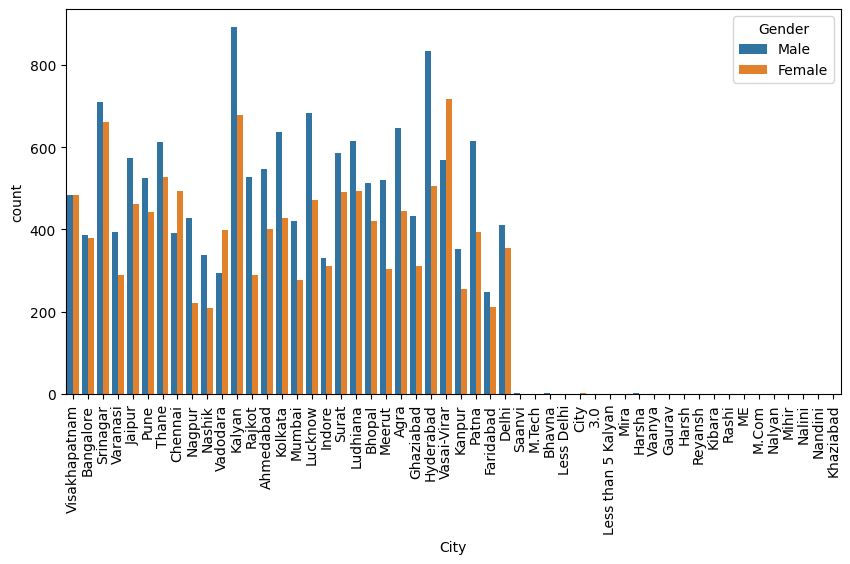

In [44]:
plt.figure(figsize=(10,5))
sns.countplot(df,x='City',hue='Gender')
plt.xticks(rotation=90)
plt.show()

## Most of the cities follow a trend that there are more males coming than females with kalyan having maximum number of males coming from.
## Visai-Virar acts as an exception where females are dominating and most of the females are cooming from there.

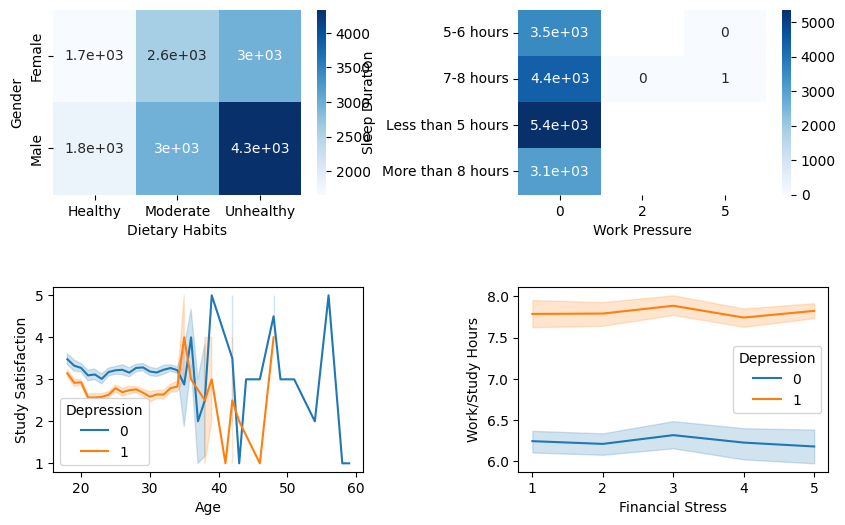

In [45]:
fig,ax=plt.subplots(2,2,figsize=(10,6))
table1=pd.pivot_table(df,'Depression','Gender','Dietary Habits',aggfunc='sum')
sns.heatmap(table1,ax=ax[0,0],cmap='Blues',annot=True)
table2=pd.pivot_table(df,'Depression','Sleep Duration','Work Pressure',aggfunc='sum')
sns.heatmap(table2,ax=ax[0,1],cmap='Blues',annot=True)
sns.lineplot(df,x='Age',y='Study Satisfaction',hue='Depression',ax=ax[1,0])
sns.lineplot(df,x='Financial Stress',y='Work/Study Hours',hue='Depression',ax=ax[1,1])
plt.subplots_adjust(wspace=0.5,hspace=0.5)
plt.show()

## Most of the Unhealthy Males are having depression.
## Overall Males have more depression as compared to females.
## People who are sleeping less than 5 hours suffer more depression.
## Non-depressed individuals maintain a higher level of study satisfaction across almost all age groups compared to depressed individuals.
## Depressed individuals report a positive relationship between financial stress and work/study hours.

In [46]:
x=df.drop(columns=['Depression'])
y=df['Depression']

In [47]:
from sklearn.preprocessing import StandardScaler,OneHotEncoder,OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split

In [48]:
print(f"Numerical Columns : {numerical}")
print(f"Categorical Columns : {categorical}")

Numerical Columns : ['Age', 'Academic Pressure', 'Work Pressure', 'CGPA', 'Study Satisfaction', 'Job Satisfaction', 'Work/Study Hours', 'Financial Stress', 'Depression']
Categorical Columns : ['Gender', 'City', 'Sleep Duration', 'Dietary Habits', 'Degree', 'Have you ever had suicidal thoughts ?', 'Family History of Mental Illness']


In [49]:
ordinal=['Dietary Habits']
nominal=[i for i in categorical if i not in ordinal]

In [50]:
print(f"Ordinal Columns : {ordinal}")
print(f"Nominal Columns : {nominal}")

Ordinal Columns : ['Dietary Habits']
Nominal Columns : ['Gender', 'City', 'Sleep Duration', 'Degree', 'Have you ever had suicidal thoughts ?', 'Family History of Mental Illness']


In [51]:
df['Dietary Habits'].unique()

array(['Healthy', 'Moderate', 'Unhealthy'], dtype=object)

In [52]:
numerical.remove('Depression')

In [53]:
ct=ColumnTransformer(transformers=[
    ('ohe',OneHotEncoder(drop='first',handle_unknown='ignore'),nominal),
    ('oe',OrdinalEncoder(categories=[['Unhealthy', 'Moderate','Healthy']]),ordinal),
    ('scaler',StandardScaler(),numerical)
])
features=ct.fit_transform(x)

In [54]:
x_train,x_test,y_train,y_test=train_test_split(features,y,test_size=0.2,random_state=42)
x_train.shape,x_test.shape,y_train.shape,y_test.shape

((22294, 93), (5574, 93), (22294,), (5574,))

In [56]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score,confusion_matrix,classification_report

In [57]:
models={
    'LogisticRegression':LogisticRegression(),
    'DecisionTreeClassifier':DecisionTreeClassifier(),
    'RandomForestClassifier':RandomForestClassifier(),
    'KNeighborsClassifier':KNeighborsClassifier(),
    'SVC':SVC()
}
scores={}
for i in range(len(list(models))):
  model=list(models.values())[i]
  model.fit(x_train,y_train)
  y_train_pred=model.predict(x_train)
  y_test_pred=model.predict(x_test)
  train_accuracy=accuracy_score(y_train,y_train_pred)
  test_accuracy=accuracy_score(y_test,y_test_pred)
  scores[list(models)[i]+'_train']=train_accuracy
  scores[list(models)[i]+'_test']=test_accuracy
  print(f'For {list(models)[i]} :')
  print(f"Training Report : {classification_report(y_train,y_train_pred)}")
  print(f"Testing Report : {classification_report(y_test,y_test_pred)}\n")

For LogisticRegression :
Training Report :               precision    recall  f1-score   support

           0       0.83      0.79      0.81      9225
           1       0.86      0.89      0.87     13069

    accuracy                           0.85     22294
   macro avg       0.85      0.84      0.84     22294
weighted avg       0.85      0.85      0.85     22294

Testing Report :               precision    recall  f1-score   support

           0       0.84      0.79      0.81      2325
           1       0.86      0.89      0.87      3249

    accuracy                           0.85      5574
   macro avg       0.85      0.84      0.84      5574
weighted avg       0.85      0.85      0.85      5574


For DecisionTreeClassifier :
Training Report :               precision    recall  f1-score   support

           0       1.00      1.00      1.00      9225
           1       1.00      1.00      1.00     13069

    accuracy                           1.00     22294
   macro avg       1

In [58]:
pd.DataFrame(list(scores.values()),index=list(scores),columns=['Accuracy'])

,Accuracy
LogisticRegression_train,0.849242
LogisticRegression_test,0.847865
DecisionTreeClassifier_train,1.000000
DecisionTreeClassifier_test,0.785971
RandomForestClassifier_train,1.000000
RandomForestClassifier_test,0.838177
KNeighborsClassifier_train,0.868350
KNeighborsClassifier_test,0.815572
SVC_train,0.868171
SVC_test,0.842662


In [59]:
list(models.values())[1]

DecisionTreeClassifier()

In [60]:
model=SVC(C=0.1)
model.fit(x_train,y_train)
y_train_pred=model.predict(x_train)
y_test_pred=model.predict(x_test)

In [61]:
confusion_matrix(y_train,y_train_pred)

array([[ 7284,  1941],
       [ 1333, 11736]])

In [62]:
confusion_matrix(y_test,y_test_pred)

array([[1820,  505],
       [ 358, 2891]])

In [63]:
type(x),type(y)

(pandas.core.frame.DataFrame, pandas.core.series.Series)

In [64]:
from sklearn.impute import SimpleImputer
predict_pipeline=Pipeline(steps=[
     ('ct',ct),
     ('model',model)
 ])
predict_pipeline.fit(x,y)

Pipeline(steps=[('ct',
                 ColumnTransformer(transformers=[('ohe',
                                                  OneHotEncoder(drop='first',
                                                                handle_unknown='ignore'),
                                                  ['Gender', 'City',
                                                   'Sleep Duration', 'Degree',
                                                   'Have you ever had suicidal '
                                                   'thoughts ?',
                                                   'Family History of Mental '
                                                   'Illness']),
                                                 ('oe',
                                                  OrdinalEncoder(categories=[['Unhealthy',
                                                                              'Moderate',
                                                                              'Healthy']]),
                                                  ['Dietary Habits']),
                                                 ('scaler', StandardScaler(),
                                                  ['Age', 'Academic Pressure',
                                                   'Work Pressure', 'CGPA',
                                                   'Study Satisfaction',
                                                   'Job Satisfaction',
                                                   'Work/Study Hours',
                                                   'Financial Stress'])])),
                ('model', SVC(C=0.1))])

In [65]:
z=df.sample()

In [66]:
z

,Gender,Age,City,Academic Pressure,Work Pressure,CGPA,Study Satisfaction,Job Satisfaction,Sleep Duration,Dietary Habits,Degree,Have you ever had suicidal thoughts ?,Work/Study Hours,Financial Stress,Family History of Mental Illness,Depression
25878,Male,34.0,Jaipur,3,0,5.1,3,0,7-8 hours,Healthy,B.Arch,Yes,7,1,Yes,1


In [67]:
predict_pipeline.predict(z.drop(columns=['Depression']))

array([0], dtype=int32)

In [68]:
import pickle
with open('pipeline.pkl','wb') as f:
  pickle.dump(predict_pipeline,f)